In [ ]:
N_INICIAL = 1000000
KAPPA = 1.2
SEMILLA = 50
NU = 1 / (1 + KAPPA / 8)   
DISCRETIZACION = "slit"

EPS_ESPACIAL = 0.0001        
SEMILLA_PUENTES = 20261115  
MAX_REFINAMIENTOS = 30
MAX_PUNTOS = 4000000    
MAX_NIVEL = 20
TOL_SERIES = 1e-8        
ORDEN_SERIES = 14
      

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def crear_particion(N, nu=None):
    k = np.arange(N + 1)
    return k / N if nu is None else (k / N) ** (2 * nu)

def crear_movimiento_browniano(t, rng):
    Delta = np.diff(t)
    dB = np.sqrt(Delta) * rng.standard_normal(Delta.size)
    B = np.zeros_like(t)
    B[1:] = np.cumsum(dB)
    return B

def crear_incrementos(kappa, t, rng, tipo="gauss", U_custom=None):
    Delta = np.diff(t)
    if U_custom is not None:
        U = np.asarray(U_custom, dtype=float)
    else:
        if tipo == "gauss":
            B = crear_movimiento_browniano(t, rng)
            U = np.sqrt(kappa) * B
            
    delta = np.diff(U)
    return Delta, delta, U

def parametros_pegado(Delta, delta):
    s = np.sqrt(delta**2 + 16.0 * Delta)
    X = np.where(delta >= 0, (delta + s) / 2.0, 0.0)
    Y = np.where(delta < 0, (-delta + s) / 2.0, 0.0)
    X = np.where(delta >= 0, X, 4.0 * Delta / np.where(Y > 0, Y, 1.0))
    Y = np.where(delta >= 0, 4.0 * Delta / np.where(X > 0, X, 1.0), Y)
    alpha = Y / (X + Y)
    return X, Y, alpha
    
def aplicar_h(tipo, Dl, dl, al, X, Y, w):
    if tipo == 0:
        s = 2.0 * np.sqrt(Dl)
        return np.sqrt(w - s) * np.sqrt(w + s) + dl
    else:
        return (w + X) ** (1.0 - al) * (w - Y) ** al

def multiplicar_series(A, B, n):
    C = np.zeros(n + 1)
    for i in range(n + 1):
        if A[i] != 0.0:
            for j in range(n + 1 - i):
                C[i + j] += A[i] * B[j]
    return C

def componer_series(F, P, n):
    R = np.zeros(n + 1)
    R[0] = F[n]
    for j in range(n - 1, 0, -1):
        R = multiplicar_series(R, P, n)
        R[0] += F[j]
    return multiplicar_series(R, P, n)

def sombrero_vertical(Dl, dl, n):
    g = np.zeros(n + 1)
    c, k = 1.0, 0
    while 2 * k + 1 <= n:
        g[2 * k + 1] = c
        k += 1
        c *= (2.0 * (2 * k - 1) / k) * Dl
    f = np.zeros(n + 1)
    c = 1.0
    for m in range(n):
        f[m + 1] = c
        c *= -dl
    return componer_series(f, g, n)

def sombrero_corte(al, X, Y, n):
    A, B = np.zeros(n + 1), np.zeros(n + 1)
    A[0], B[0] = 1.0, 1.0
    for k in range(1, n + 1):
        A[k] = A[k - 1] * ((1.0 - al) + k - 1) / k * (-X)
        B[k] = B[k - 1] * (al + k - 1) / k * Y
    C = multiplicar_series(A, B, n)
    salida = np.zeros(n + 1)
    salida[1:] = C[:n]
    return salida

def evaluar_serie_inversa(A, w, n):
    u = 1.0 / w
    s = A[n] + 0.0j
    for j in range(n - 1, -1, -1):
        s = s * u + A[j]
    return 1.0 / s

def _corte_rplus(al, X, Y, w):
    lo, hi = Y, Y + X + w + 1e-12
    while (hi - Y) ** al * (hi + X) ** (1.0 - al) < w:
        hi = Y + 2.0 * (hi - Y)
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        if (mid - Y) ** al * (mid + X) ** (1.0 - al) < w:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def _corte_rminus(al, X, Y, w):
    ww, lo, hi = -w, X, X + Y + (-w) + 1e-12
    while (hi - X) ** (1.0 - al) * (hi + Y) ** al < ww:
        hi = X + 2.0 * (hi - X)
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        if (mid - X) ** (1.0 - al) * (mid + Y) ** al < ww:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def radio_bloque(tipo, Dl, dl, al, X, Y, s, b):
    A, B = 0.0, 0.0
    for m in range(s, s + b):
        if tipo == 0:
            p = dl[m]
            if m == s:
                A = 2.0 * np.sqrt(Dl[m])
                B = A
            else:
                yhi, ylo = max(B, p), min(-A, p)
                B = np.sqrt((yhi - p) ** 2 + 4.0 * Dl[m])
                A = np.sqrt((ylo - p) ** 2 + 4.0 * Dl[m])
        else:
            if m == s:
                A, B = X[m], Y[m]
            else:
                yhi, ylo = max(B, 0.0), min(-A, 0.0)
                B = _corte_rplus(al[m], X[m], Y[m], yhi)
                A = _corte_rminus(al[m], X[m], Y[m], ylo)
    return max(A, B)

def precalcular_bloques(tipo, Dl, dl, al, X, Y, b, M, n):
    Ahat = np.zeros((M, n + 1))
    R = np.zeros(M)
    for j in range(M):
        s = j * b
        P = sombrero_vertical(Dl[s + b - 1], dl[s + b - 1], n) if tipo == 0 else sombrero_corte(al[s + b - 1], X[s + b - 1], Y[s + b - 1], n)
        for i in range(s + b - 2, s - 1, -1):
            F = sombrero_vertical(Dl[i], dl[i], n) if tipo == 0 else sombrero_corte(al[i], X[i], Y[i], n)
            P = componer_series(F, P, n)
        Ahat[j, :] = P
        R[j] = radio_bloque(tipo, Dl, dl, al, X, Y, s, b)
    return Ahat, R

class SLEDiscreto:
    def __init__(self, N, kappa, discretizacion="vertical", nu=None,
                 incrementos="gauss", semilla=0, U_custom=None, t_custom=None):
        self.N, self.kappa = int(N), float(kappa)
        self.tipo = 0 if discretizacion == "vertical" else 1
        self.incrementos = incrementos
        rng = np.random.default_rng(semilla)
        self.t = (crear_particion(self.N, nu) if t_custom is None
                  else np.asarray(t_custom, dtype=float).copy())
        if U_custom is not None:
            U_custom = np.asarray(U_custom, dtype=float).copy()
        self.Dl, self.dl, self.U = crear_incrementos(
            self.kappa, self.t, rng, incrementos, U_custom=U_custom
        )
        self.X, self.Y, self.al = parametros_pegado(self.Dl, self.dl)

    def estandar(self, ks):
        ks = np.asarray(ks, dtype=int)
        salida = np.empty(ks.size, dtype=complex)
        for idx, k in enumerate(ks):
            w = 0.0 + 0.0j
            for i in range(k - 1, -1, -1):
                w = aplicar_h(self.tipo, self.Dl[i], self.dl[i], self.al[i], self.X[i], self.Y[i], w)
            salida[idx] = w
        return salida

    def preparar(self, b=None, n=12, L=None, tol=1e-6):
        N = self.N
        b = max(2, int(round(0.12 * np.sqrt(N)))) if b is None else b
        L = tol ** (-1.0 / n) if L is None else L
        M = N // b
        t0 = time.perf_counter()
        self.Ahat, self.R = precalcular_bloques(self.tipo, self.Dl, self.dl, self.al, self.X, self.Y, b, M, n)
        self.t_pre = time.perf_counter() - t0
        self.b, self.n, self.L = b, n, L

    def rapido(self, ks):
        ks = np.asarray(ks, dtype=int)
        salida = np.empty(ks.size, dtype=complex)
        for idx, k in enumerate(ks):
            m = k // self.b
            w = 0.0 + 0.0j
            for i in range(k - 1, m * self.b - 1, -1):
                w = aplicar_h(self.tipo, self.Dl[i], self.dl[i], self.al[i], self.X[i], self.Y[i], w)
            for j in range(m - 1, -1, -1):
                if abs(w) >= self.L * self.R[j]:
                    w = evaluar_serie_inversa(self.Ahat[j], w, self.n)
                else:
                    for i in range(j * self.b + self.b - 1, j * self.b - 1, -1):
                        w = aplicar_h(self.tipo, self.Dl[i], self.dl[i], self.al[i], self.X[i], self.Y[i], w)
            salida[idx] = w
        return salida

In [ ]:
import warnings
from dataclasses import dataclass


def rapido_todos(sle):
    if not hasattr(sle, "Ahat"):
        sle.preparar()
    salida = np.zeros(sle.N, dtype=np.complex128)
    for j in range((sle.N - 1) // sle.b, -1, -1):
        inicio, fin = j * sle.b, min(sle.N, (j + 1) * sle.b)
        local = np.zeros(fin - inicio, dtype=np.complex128)
        for i in range(fin - 1, inicio - 1, -1):
            local[i - inicio:] = aplicar_h(
                sle.tipo, sle.Dl[i], sle.dl[i], sle.al[i],
                sle.X[i], sle.Y[i], local[i - inicio:]
            )
        salida[inicio:fin] = local
        if fin == sle.N:
            continue
        resto = salida[fin:]
        lejos = np.abs(resto) >= sle.L * sle.R[j]
        if np.any(lejos):
            resto[lejos] = evaluar_serie_inversa(sle.Ahat[j], resto[lejos], sle.n)
        cerca = ~lejos
        if np.any(cerca):
            w = resto[cerca]
            for i in range(fin - 1, inicio - 1, -1):
                w = aplicar_h(sle.tipo, sle.Dl[i], sle.dl[i], sle.al[i],
                              sle.X[i], sle.Y[i], w)
            resto[cerca] = w
    return salida


def insertar_puentes(t, U, kappa, indices, niveles, rng):
    indices = np.asarray(indices, dtype=int)
    a, b = t[indices], t[indices + 1]
    m = a + (b - a) / 2.0
    Um = (U[indices] + U[indices + 1]) / 2.0
    Um += np.sqrt(kappa * (b - a) / 4.0) * rng.standard_normal(len(indices))

    t_nuevo = np.insert(t, indices + 1, m)
    U_nuevo = np.insert(U, indices + 1, Um)
    niveles_nuevos = niveles.copy()
    niveles_nuevos[indices] += 1
    niveles_nuevos = np.insert(niveles_nuevos, indices + 1, niveles[indices] + 1)
    return t_nuevo, U_nuevo, niveles_nuevos


@dataclass
class ResultadoAdaptativo:
    s: object
    z: np.ndarray         
    t_base: np.ndarray
    U_base: np.ndarray
    z_base: np.ndarray
    historial: list
    convergio: bool
    motivo: str
    epsilon: float


def refinar_sle(s_inicial, epsilon=0.01, semilla_puentes=20261115,
                max_refinamientos=16, max_puntos=400_000, max_nivel=30,
                tol_series=1e-8, orden_series=14, z_inicial=None,
                verbose=True):

    rng = np.random.default_rng(semilla_puentes)
    s = s_inicial
    t_base, U_base = s.t.copy(), s.U.copy()
    niveles = np.zeros(s.N, dtype=int)
    historial, z_base = [], None
    inicio_total = time.perf_counter()
    convergio = False

    for ronda in range(max_refinamientos + 1):
        inicio_ronda = time.perf_counter()
        if ronda == 0 and z_inicial is not None:
            puntos = np.asarray(z_inicial, dtype=complex).copy()
        else:
            s.preparar(n=orden_series, tol=tol_series)
            puntos = rapido_todos(s)
        z = np.r_[0j, puntos]
        if z_base is None:
            z_base = z.copy()
        saltos = np.abs(np.diff(z))
        grandes = np.flatnonzero(saltos > epsilon)
        fila = dict(ronda=ronda, N=s.N, salto_max=float(saltos.max()),
                    pendientes=len(grandes), dt_min=float(s.Dl.min()),
                    segundos=time.perf_counter() - inicio_ronda)
        historial.append(fila)
        if verbose:
            print(f"Ronda {ronda:2d} | N={s.N:,} | salto máx={fila['salto_max']:.6g} "
                  f"| pendientes={len(grandes):,} | {fila['segundos']:.1f} s", flush=True)

        # Estos son limites de seguridad porque como la generación del browniano es aleatoria, para kappas umy grandes
        # puede generar nuevas iteraciones para siempre porque el browniano puede moverse mucho!!
        # Las verificación de errores fueron asistidas con la IA
            
        if not len(grandes):
            convergio, motivo = True, "Todos los saltos calculados son <= epsilon."
            break
        if ronda == max_refinamientos:
            motivo = "Se alcanzó max_refinamientos antes de cumplir epsilon."
            break
        disponibles = int(max_puntos - s.N)
        if disponibles <= 0:
            motivo = "Se alcanzó max_puntos antes de cumplir epsilon."
            break
        medios = s.t[:-1] + s.Dl / 2.0
        divisible = ((medios > s.t[:-1]) & (medios < s.t[1:])
                     & (niveles < max_nivel))
        elegidos = grandes[divisible[grandes]]
        if not len(elegidos):
            motivo = "Límite de profundidad o precisión temporal en los intervalos pendientes."
            break
        if len(elegidos) > disponibles:
            orden = np.argsort(-saltos[elegidos], kind="stable")[:disponibles]
            elegidos = elegidos[orden]
        elegidos = np.sort(elegidos)
        t_nuevo, U_nuevo, niveles = insertar_puentes(
            s.t, s.U, s.kappa, elegidos, niveles, rng
        )
        s = SLEDiscreto(len(t_nuevo) - 1, s.kappa,
                        discretizacion="vertical" if s.tipo == 0 else "slit",
                        U_custom=U_nuevo, t_custom=t_nuevo)

    posiciones = np.searchsorted(s.t, t_base)
    assert np.array_equal(s.t[posiciones], t_base)
    assert np.array_equal(s.U[posiciones], U_base)


    if not convergio:
        warnings.warn(motivo + " El resultado se devuelve marcado como NO convergido.",
                      RuntimeWarning, stacklevel=2)
    if verbose:
        print(f"{motivo} Tiempo total: {time.perf_counter() - inicio_total:.1f} s.")
    return ResultadoAdaptativo(s, z, t_base, U_base, z_base,
                              historial, convergio, motivo, float(epsilon))

In [4]:
def comprobaciones_rapidas():
    for tipo in ("vertical", "slit"):
        s0 = SLEDiscreto(80, 0.0, discretizacion=tipo, nu=0.8)
        s0.preparar(n=14, tol=1e-10)
        np.testing.assert_allclose(rapido_todos(s0), 2j * np.sqrt(s0.t[1:]),
                                   rtol=1e-8, atol=1e-9)
        s1 = SLEDiscreto(91, 4.0, discretizacion=tipo, nu=0.7, semilla=9)
        s1.preparar(n=14, tol=1e-10)
        ks = np.arange(1, s1.N + 1)
        np.testing.assert_allclose(rapido_todos(s1), s1.rapido(ks), atol=1e-10)
        np.testing.assert_allclose(rapido_todos(s1), s1.estandar(ks),
                                   rtol=1e-7, atol=1e-8)
    t0, U0 = np.array([0., 0.3, 1.]), np.array([0., -0.2, 0.7])
    tn, Un, niveles = insertar_puentes(t0, U0, 2., np.array([0, 1]),
                                       np.zeros(2, dtype=int), np.random.default_rng(10))
    posiciones = np.searchsorted(tn, t0)
    np.testing.assert_array_equal(tn[posiciones], t0)
    np.testing.assert_array_equal(Un[posiciones], U0)
    np.testing.assert_array_equal(niveles, [1, 1, 1, 1])
    assert np.all(np.diff(tn) > 0)
    print("Comprobaciones rápidas: OK.")

comprobaciones_rapidas()

Comprobaciones rápidas: OK.


In [ ]:
s_base = SLEDiscreto(
    N_INICIAL, KAPPA, discretizacion=DISCRETIZACION,
    nu=NU, incrementos="gauss", semilla=SEMILLA
)

resultado = refinar_sle(
    s_base,
    epsilon=EPS_ESPACIAL,
    semilla_puentes=SEMILLA_PUENTES,
    max_refinamientos=MAX_REFINAMIENTOS,
    max_puntos=MAX_PUNTOS,
    max_nivel=MAX_NIVEL,
    tol_series=TOL_SERIES,
    orden_series=ORDEN_SERIES,
)


s_super = resultado.s
N_super = s_super.N
z_pts = resultado.z[1:]
print(f"N inicial: {N_INICIAL:,}; N final: {N_super:,}; convergió: {resultado.convergio}")

Ronda  0 | N=1,000,000 | salto máx=0.000424117 | pendientes=497 | 1844.2 s
Ronda  1 | N=1,000,497 | salto máx=0.000265896 | pendientes=200 | 1816.8 s
Ronda  2 | N=1,000,697 | salto máx=0.000231519 | pendientes=63 | 2994.8 s
Ronda  3 | N=1,000,760 | salto máx=0.000136621 | pendientes=13 | 2043.1 s
Ronda  4 | N=1,000,773 | salto máx=0.00010637 | pendientes=3 | 2001.3 s
Ronda  5 | N=1,000,776 | salto máx=9.97065e-05 | pendientes=0 | 2010.8 s
Todos los saltos calculados son <= epsilon. Tiempo total: 12711.5 s.
N inicial: 1,000,000; N final: 1,000,776; convergió: True


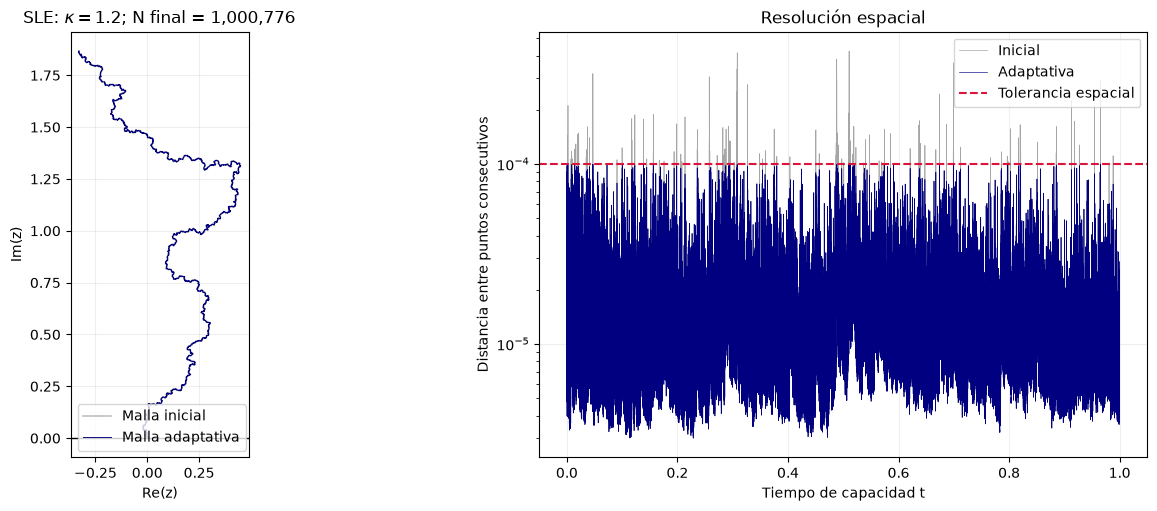

Salto máximo inicial: 0.00042411691
Salto máximo final:   9.9706534e-05
Menor paso temporal: 3.6746619e-11
Todos los saltos calculados son <= epsilon.


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
zb, zr = resultado.z_base, resultado.z
axs[0].plot(zb.real, zb.imag, color="0.65", lw=1.2, alpha=0.7, label="Malla inicial")
axs[0].plot(zr.real, zr.imag, color="navy", lw=0.65, label="Malla adaptativa")
axs[0].axhline(0, color="black", lw=1)
axs[0].set_aspect("equal", adjustable="box")
axs[0].set(xlabel="Re(z)", ylabel="Im(z)",
           title=rf"SLE: $\kappa={s_super.kappa:g}$; N final = {s_super.N:,}")
axs[0].legend()
axs[0].grid(alpha=0.2)

salto_base = np.abs(np.diff(zb))
salto_final = np.abs(np.diff(zr))
axs[1].semilogy(resultado.t_base[1:], np.maximum(salto_base, 1e-16),
                color="0.65", lw=0.5, label="Inicial")
axs[1].semilogy(s_super.t[1:], np.maximum(salto_final, 1e-16),
                color="navy", lw=0.45, label="Adaptativa")
axs[1].axhline(EPS_ESPACIAL, color="crimson", ls="--", label="Tolerancia espacial")
axs[1].set(xlabel="Tiempo de capacidad t", ylabel="Distancia entre puntos consecutivos",
           title="Resolución espacial")
axs[1].legend()
axs[1].grid(alpha=0.2)
plt.show()

print(f"Salto máximo inicial: {salto_base.max():.8g}")
print(f"Salto máximo final:   {salto_final.max():.8g}")
print(f"Menor paso temporal: {s_super.Dl.min():.8g}")
print(resultado.motivo)

In [ ]:
## Código de generación de video asistido con IA!!

from matplotlib.animation import FuncAnimation, FFMpegWriter

def crear_video_sle(t, z, kappa, archivo="sle_adaptativo.mp4", *,
                    modo="capacidad", duracion=20, fps=60, dpi=160):
    try:
        import imageio_ffmpeg
    except ImportError as exc:
        raise ImportError("Ejecuta %pip install imageio-ffmpeg y repite esta celda.") from exc
    t, z = np.asarray(t, dtype=float), np.asarray(z, dtype=complex)
    if (len(t) != len(z) or len(t) < 2 or np.any(np.diff(t) <= 0)
            or not np.all(np.isfinite(t)) or not np.all(np.isfinite(z))):
        raise ValueError("t y z deben ser finitos, tener igual longitud y t creciente.")
    if fps <= 0 or duracion <= 0 or dpi <= 0:
        raise ValueError("fps, duracion y dpi deben ser positivos.")
    if modo == "capacidad":
        reloj = t
    elif modo == "detalle":
        reloj = np.r_[0., np.cumsum(np.abs(np.diff(z)))]
        if reloj[-1] == 0:
            raise ValueError("La trayectoria no tiene longitud poligonal positiva.")
    else:
        raise ValueError("modo debe ser 'capacidad' o 'detalle'.")

    objetivos = np.linspace(reloj[0], reloj[-1], max(2, int(fps * duracion)))
    indices = np.clip(np.searchsorted(reloj, objetivos, side="right") - 1, 0, len(z) - 2)
    denominador = reloj[indices + 1] - reloj[indices]
    fraccion = np.divide(objetivos - reloj[indices], denominador,
                         out=np.ones_like(objetivos), where=denominador > 0)
    fraccion = np.clip(fraccion, 0., 1.)
    puntas = z[indices] + fraccion * (z[indices + 1] - z[indices])
    tiempos = t[indices] + fraccion * (t[indices + 1] - t[indices])
    # Recorrido sobre la poligonal: detecta también avances con mucho retorno.
    longitud = np.r_[0., np.cumsum(np.abs(np.diff(z)))]
    recorridos = longitud[indices] + fraccion * (longitud[indices + 1] - longitud[indices])
    print(f"Mayor recorrido por fotograma: {np.diff(recorridos).max():.5g}")
    print(f"Video: {len(objetivos)} fotogramas, modo={modo}, reloj t visible.")

    ajustes = {"animation.ffmpeg_path": imageio_ffmpeg.get_ffmpeg_exe(),
               "path.simplify": False, "savefig.bbox": None}
    with plt.rc_context(ajustes):
        fig, ax = plt.subplots(figsize=(12, 6.75), constrained_layout=True)
        margen = .05 * max(np.ptp(z.real), np.ptp(z.imag), 1e-6)
        ax.set(xlim=(z.real.min()-margen, z.real.max()+margen),
               ylim=(-margen, z.imag.max()+margen), xlabel="Re(z)", ylabel="Im(z)")
        ax.set_aspect("equal", adjustable="box")
        ax.axhline(0, color="black", lw=1)
        ax.grid(alpha=.2)
        subtitulo = "tiempo de capacidad" if modo == "capacidad" else "reproducción por distancia poligonal"
        ax.set_title(rf"SLE $\kappa={kappa:g}$ — {subtitulo}")
        linea, = ax.plot([], [], color="navy", lw=.7)
        punta, = ax.plot([], [], "o", color="crimson", ms=4)
        texto = ax.text(.02, .97, "", transform=ax.transAxes, va="top")

        def actualizar(i):
            j = indices[i]
            visible = np.r_[z[:j+1], puntas[i]]
            linea.set_data(visible.real, visible.imag)
            punta.set_data([puntas[i].real], [puntas[i].imag])
            texto.set_text(f"t = {tiempos[i]:.6f}\nN = {len(z)-1:,}")
            return linea, punta, texto

        anim = FuncAnimation(fig, actualizar, frames=len(objetivos), interval=1000/fps,
                             blit=True, repeat=False, cache_frame_data=False)
        writer = FFMpegWriter(fps=fps, codec="libx264",
                             extra_args=["-crf", "18", "-pix_fmt", "yuv420p", "-movflags", "+faststart"])
        try:
            anim.save(archivo, writer=writer, dpi=dpi)
        finally:
            plt.close(fig)
    return archivo


GENERAR_VIDEO = True     
MODO_VIDEO = "capacidad"  
DURACION_VIDEO = 20        
FPS_VIDEO = 120
DPI_VIDEO = 160     

if GENERAR_VIDEO:
    from IPython.display import Video, display
    archivo_video = crear_video_sle(
        s_super.t, resultado.z, s_super.kappa, modo=MODO_VIDEO,
        duracion=DURACION_VIDEO, fps=FPS_VIDEO, dpi=DPI_VIDEO
    )
    display(Video(archivo_video, embed=True))
else:
    print("Para exportar, cambia GENERAR_VIDEO=True y ejecuta esta celda.")

Mayor recorrido por fotograma: 0.13003
Video: 2400 fotogramas, modo=capacidad, reloj t visible.
